# 05 - Next-day PM2.5 forecast

**Question:** at the end of a day, can the next day's mean PM2.5 of each district be predicted better than by assuming that tomorrow equals today?

**Setup**
- **Unit:** one row per district and issue day *d*; the target is the daily mean PM2.5 of day *d+1* (rows with a missing target are dropped).
- **Features** (only data available at the end of day *d*): pollutant means of day *d*, PM2.5 lags of 1, 2, 3 and 6 days, a 7-day rolling mean, the city-wide mean of day *d* and its change from the day before, the day of year and weekday of the target day, and the station.
- **Split by time, never at random:** fit on targets in 2017-2018, test on targets in 2019. Settings are tuned with 3 expanding-window folds inside 2018 (validation quarters Q2, Q3 and Q4); the test year is used once, after the choice.
- **Metrics:** MAE (main), RMSE, bias, accuracy of the Korean grade, and precision / recall of the "Bad or worse" alert (a missed bad day is the costly error).

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
import json

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from seoul_air.features import FEATURE_COLUMNS, make_forecast_table
from seoul_air.metrics import all_metrics
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 2. Forecast table

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
table = make_forecast_table(daily)
table = table.dropna(subset=["target"]).reset_index(drop=True)

train = table[table["target_date"] <= config.TRAIN_END].reset_index(drop=True)
test = table[table["target_date"] >= config.TEST_START].reset_index(drop=True)
print(f"Train: {len(train):,} rows, targets {train['target_date'].min().date()} to {train['target_date'].max().date()}")
print(f"Test:  {len(test):,} rows, targets {test['target_date'].min().date()} to {test['target_date'].max().date()}")
print("Missing feature values in train (%):")
print(train[FEATURE_COLUMNS].isna().mean().mul(100).round(2)[lambda s: s > 0].to_string())

Train: 17,825 rows, targets 2017-01-02 to 2018-12-31
Test:  8,397 rows, targets 2019-01-01 to 2019-12-31
Missing feature values in train (%):
pm25_d0             1.00
pm10_d0             1.24
no2_d0              0.96
co_d0               1.65
o3_d0               1.35
so2_d0              1.42
pm25_lag1           1.58
pm25_lag2           1.84
pm25_lag3           2.04
pm25_lag6           2.60
pm25_roll7          1.35
pm25_city_change    0.14


In [3]:
# Expanding-window folds inside the fit period: validate on 2018 Q2, Q3 and Q4
folds = []
for start, end in [("2018-04-01", "2018-06-30"), ("2018-07-01", "2018-09-30"), ("2018-10-01", "2018-12-31")]:
    fit_idx = np.where(train["target_date"] < start)[0]
    val_idx = np.where((train["target_date"] >= start) & (train["target_date"] <= end))[0]
    folds.append((fit_idx, val_idx))
    print(f"fold: fit {len(fit_idx):,} rows | validate {start} to {end}: {len(val_idx):,} rows")

X_train, y_train = train[FEATURE_COLUMNS], train["target"]
X_test, y_test = test[FEATURE_COLUMNS], test["target"]
numeric = [c for c in FEATURE_COLUMNS if c not in ("station_code", "target_weekday")]
categorical = ["station_code", "target_weekday"]

fold: fit 11,081 rows | validate 2018-04-01 to 2018-06-30: 2,243 rows
fold: fit 13,324 rows | validate 2018-07-01 to 2018-09-30: 2,259 rows
fold: fit 15,583 rows | validate 2018-10-01 to 2018-12-31: 2,242 rows


## 3. Baselines

In [4]:
train_mean = y_train.mean()
# Persistence: tomorrow = today (falls back to the 7-day mean, then the training mean, when today is missing)
persistence = X_test["pm25_d0"].fillna(X_test["pm25_roll7"]).fillna(train_mean)

# Climatology: training mean of the same station and month of the target day
clim = train.assign(m=train["target_date"].dt.month).groupby(["station_code", "m"])["target"].mean()
climatology = pd.Series(
    clim.reindex(list(zip(test["station_code"], test["target_date"].dt.month))).to_numpy(), index=test.index
).fillna(train_mean)

predictions = {"persistence": persistence.to_numpy(), "climatology": climatology.to_numpy()}

## 4. Models

In [5]:
ridge = make_pipeline(
    ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ]),
    Ridge(),
)
ridge_search = GridSearchCV(ridge, {"ridge__alpha": [0.1, 1, 10, 100]}, cv=folds,
                            scoring="neg_mean_absolute_error")
ridge_search.fit(X_train, y_train)
print("Ridge best alpha:", ridge_search.best_params_, "| CV MAE:", round(-ridge_search.best_score_, 3))

Ridge best alpha: {'ridge__alpha': 100} | CV MAE: 6.801


In [6]:
hgb = HistGradientBoostingRegressor(
    categorical_features=[FEATURE_COLUMNS.index(c) for c in categorical], random_state=42)
hgb_grid = {
    "learning_rate": [0.03, 0.1],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [20, 80],
    "max_iter": [200, 400],
    "loss": ["squared_error", "absolute_error"],
}
hgb_search = GridSearchCV(hgb, hgb_grid, cv=folds, scoring="neg_mean_absolute_error", n_jobs=-1)
hgb_search.fit(X_train.astype(float), y_train)
print("HGB best settings:", hgb_search.best_params_, "| CV MAE:", round(-hgb_search.best_score_, 3))

HGB best settings: {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 20} | CV MAE: 6.992


In [7]:
# Baselines scored on the same validation folds, so the choice is made without the test year
def cv_mae(pred_fn):
    return np.mean([np.mean(np.abs(pred_fn(train.iloc[f], train.iloc[v]) - train.iloc[v]["target"])) for f, v in folds])

cv_scores = pd.Series({
    "persistence": cv_mae(lambda f, v: v["pm25_d0"].fillna(v["pm25_roll7"]).fillna(f["target"].mean())),
    "ridge": -ridge_search.best_score_,
    "hist_gradient_boosting": -hgb_search.best_score_,
}).sort_values()
print("Validation MAE (mean of 3 folds):")
print(cv_scores.round(3).to_string())
selected = cv_scores.idxmin()
print("Selected model (lowest validation MAE):", selected)

Validation MAE (mean of 3 folds):
ridge                     6.801
hist_gradient_boosting    6.992
persistence               7.296
Selected model (lowest validation MAE): ridge


**Interpretation.** On the validation folds (2018 Q2-Q4) Ridge has the lowest MAE (6.801 ug/m3), ahead of gradient boosting (6.992) and persistence (7.296). The selected settings (Ridge with alpha 100; boosting with a small learning rate, 15 leaves and absolute-error loss) indicate that the signal is mostly linear and the data is small, so the simpler model wins. Ridge is selected before looking at 2019.

## 5. Test year (2019), evaluated once

In [8]:
predictions["ridge"] = ridge_search.predict(X_test)
predictions["hist_gradient_boosting"] = hgb_search.predict(X_test.astype(float))

rows = []
for name, pred in predictions.items():
    m = all_metrics(y_test, pred)
    rows.append({"model": name, **m})
    (config.METRICS / f"05_{name}.json").write_text(json.dumps({"test_year": 2019, **m}, indent=2))
leaderboard = pd.DataFrame(rows).set_index("model").sort_values("mae")
leaderboard.to_csv(config.METRICS / "05_leaderboard.csv")
skill = 1 - leaderboard.loc[selected, "mae"] / leaderboard.loc["persistence", "mae"]
print(f"Selected model: {selected}; MAE improvement over persistence: {skill:.1%}")
leaderboard.round(3)

Selected model: ridge; MAE improvement over persistence: 10.0%


,mae,rmse,bias,grade_accuracy,bad_precision,bad_recall,bad_f1
model,,,,,,,
ridge,7.970,11.829,-1.089,0.653,0.702,0.540,0.610
hist_gradient_boosting,8.678,13.191,-1.115,0.646,0.661,0.519,0.581
persistence,8.859,13.093,0.038,0.638,0.615,0.609,0.612
climatology,10.832,16.437,-1.223,0.549,0.514,0.136,0.215


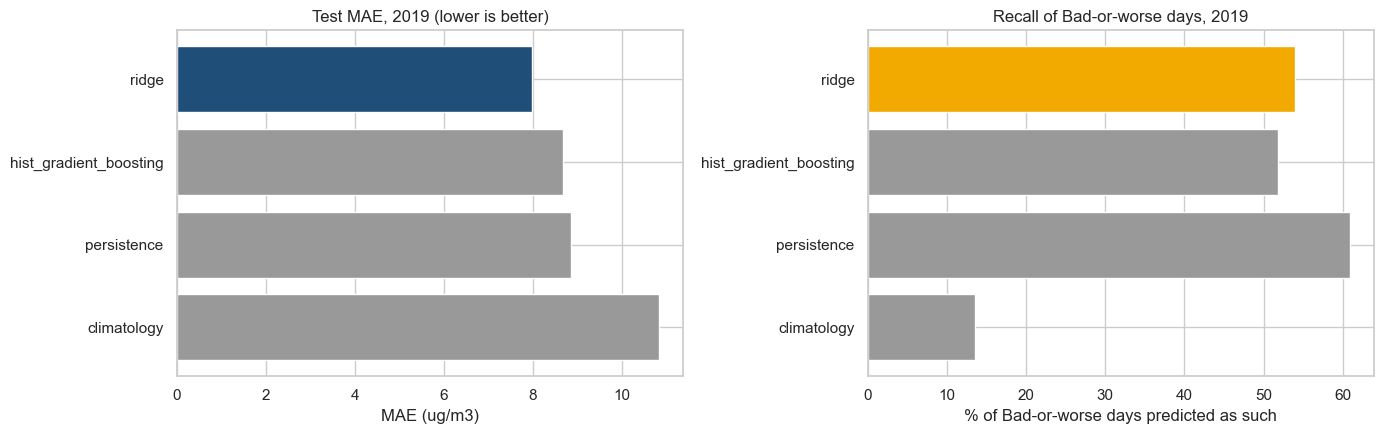

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lb = leaderboard.sort_values("mae", ascending=False)
axes[0].barh(lb.index, lb["mae"], color=["#1f4e79" if i == selected else "0.6" for i in lb.index])
axes[0].set_title("Test MAE, 2019 (lower is better)")
axes[0].set_xlabel("MAE (ug/m3)")
axes[1].barh(lb.index, lb["bad_recall"] * 100, color=["#f2a900" if i == selected else "0.6" for i in lb.index])
axes[1].set_title("Recall of Bad-or-worse days, 2019")
axes[1].set_xlabel("% of Bad-or-worse days predicted as such")
fig.tight_layout()
fig.savefig(config.FIGURES / "05_leaderboard.png", dpi=120)
plt.show()

**Interpretation.** On 2019, Ridge has a MAE of 7.970 ug/m3, 10.0% lower than persistence (8.859) and well below climatology (10.832); the test confirms the validation ranking. The gain is in the size of the errors, not in the alerts: Ridge raises fewer false alarms (Bad precision 0.702 against 0.615) but misses more Bad days (recall 0.540 against 0.609), so its F1 on Bad days (0.610) equals that of persistence (0.612). Like most regression models it shrinks towards the mean (bias -1.089 ug/m3), which under-predicts peaks. For a public alert, a lower decision threshold or a model trained for the 'Bad' class would trade precision for recall.

## 6. Error analysis

Test MAE by month of the target day:
target_date     1      2      3     4      5     6     7     8     9     10    11    12
ridge        12.93   9.62  17.52  6.73   9.68  6.90  7.26  4.36  3.94  4.77  5.59  7.77
persistence  15.34  10.89  18.29  6.17  10.86  7.96  7.47  5.15  4.03  5.98  6.35  9.03


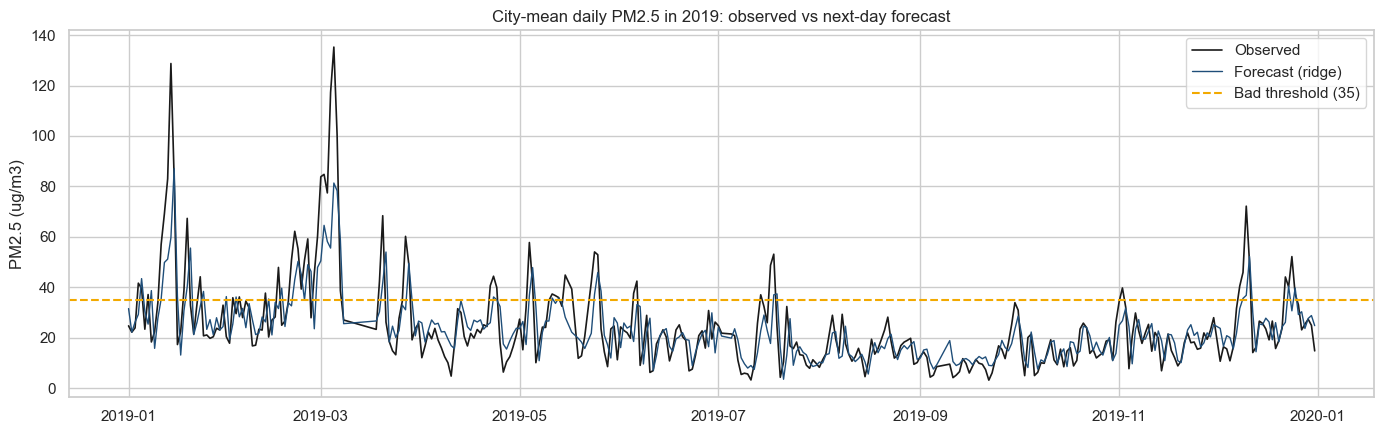

In [10]:
res = test[["station_code", "target_date", "target"]].copy()
res["pred"] = predictions[selected]
res["persistence"] = predictions["persistence"]
res["abs_err"] = (res["pred"] - res["target"]).abs()
res["abs_err_persistence"] = (res["persistence"] - res["target"]).abs()

by_month = res.groupby(res["target_date"].dt.month)[["abs_err", "abs_err_persistence"]].mean()
by_month.columns = [selected, "persistence"]
print("Test MAE by month of the target day:")
print(by_month.round(2).T.to_string())

city_res = res.groupby("target_date")[["target", "pred", "persistence"]].mean()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(city_res.index, city_res["target"], color="k", lw=1.2, label="Observed")
ax.plot(city_res.index, city_res["pred"], color="#1f4e79", lw=1, label=f"Forecast ({selected})")
ax.axhline(35, color="#f2a900", ls="--", label="Bad threshold (35)")
ax.set_title("City-mean daily PM2.5 in 2019: observed vs next-day forecast")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "05_forecast_2019.png", dpi=120)
plt.show()

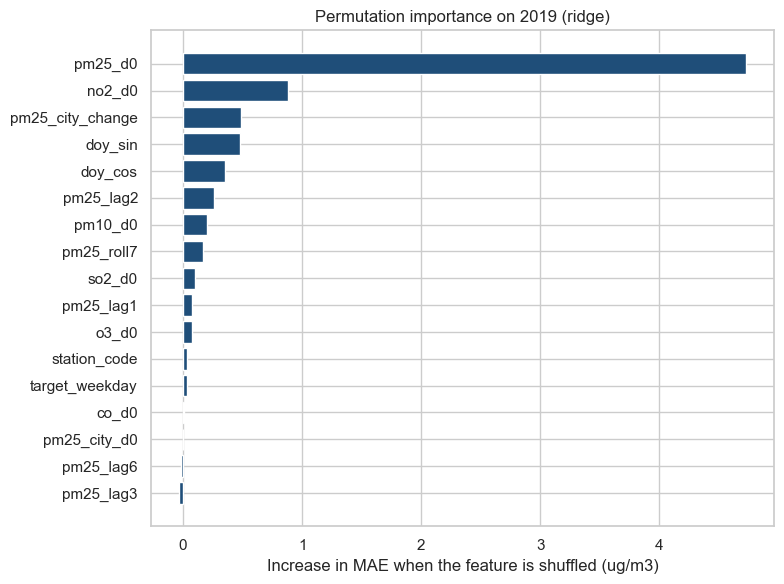

pm25_d0             4.727
no2_d0              0.885
pm25_city_change    0.488
doy_sin             0.475
doy_cos             0.351


In [11]:
best_model = {"ridge": ridge_search, "hist_gradient_boosting": hgb_search}.get(selected)
if best_model is not None:
    X_imp = X_test.astype(float) if selected == "hist_gradient_boosting" else X_test
    imp = permutation_importance(best_model.best_estimator_, X_imp, y_test, n_repeats=5,
                                 random_state=42, scoring="neg_mean_absolute_error")
    importance = pd.Series(imp.importances_mean, index=FEATURE_COLUMNS).sort_values()
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(importance.index, importance.values, color="#1f4e79")
    ax.set_title(f"Permutation importance on 2019 ({selected})")
    ax.set_xlabel("Increase in MAE when the feature is shuffled (ug/m3)")
    fig.tight_layout()
    fig.savefig(config.FIGURES / "05_feature_importance.png", dpi=120)
    plt.show()
    print(importance.sort_values(ascending=False).head(5).round(3).to_string())

**Interpretation.** Errors are largest in the high-pollution months (Ridge MAE 17.52 in March and 12.93 in January) and smallest in September (3.94). Ridge beats persistence in 11 of the 12 months; the exception is April (6.73 against 6.17). The most important feature by far is today's PM2.5 (shuffling it raises the MAE by 4.727), followed by today's NO2 (0.885), the city-wide change from the day before (0.488) and the season (day of year). The model mostly refines persistence; sudden changes driven by weather remain the main source of error.

## 7. Limitations

- **No weather data.** Wind, rain and humidity drive day-to-day PM2.5 changes; without them (or a weather forecast for day *d+1*) sudden changes are hard to predict. Adding KMA observations and forecasts is the main next step.
- **Three years only.** Two years to fit and one to test; the model has seen each season only twice.
- **Daily means, issued at midnight.** An operational forecast would be issued earlier (for example at 17:00 KST) with fewer hours of day *d*.
- **One station per district.** District values are station values and may not represent the whole district.